# 📘 5.1 Linear Regression

### Learning a defensible engineering calibration model

Engineering decisions often require us to learn a relationship from measured data:

* converting a sensor voltage into force;
* estimating heat loss from temperature and airflow;
* predicting energy use from operating conditions;
* estimating drag from geometry and speed; or
* constructing a fast surrogate for an expensive simulation.

**Linear regression** is an important starting point because it is fast, interpretable
and widely used. It also gives us a clear workflow that will carry into the more
flexible regression methods later in Week 5.

A fitted line is not automatically a trustworthy engineering model. We still need to
check the data domain, residuals, validation performance, physical meaning and
sensitivity to unusual observations.


### 🎯 Learning Objectives

By the end of this notebook, you should be able to:

* distinguish **features**, **targets**, **predictions** and **residuals**;
* explain the least-squares objective used by ordinary linear regression;
* fit simple and multiple linear regression models with scikit-learn;
* interpret an intercept and coefficients using engineering units;
* separate training data from validation data;
* compare a regression model with a simple baseline;
* inspect residuals and recognise unsupported extrapolation; and
* explain why outliers, nonlinear behaviour and poor data coverage can make a
  plausible-looking model unsafe.

### 🔗 Unit Learning Outcome Alignment

This notebook supports the following MMA3001 learning outcomes:

* **LO1:** Assess the suitability and limitations of numerical analysis and machine
  learning tools for engineering applications.
* **LO2:** Demonstrate effective use of numerical analysis and machine learning tools
  to develop defensible solutions to open-ended engineering problems.
* **LO3:** Apply appropriate mathematical and numerical techniques to solve common
  engineering problems, and evaluate performance, error, stability and accuracy.

### 📚 Sources used in this notebook

* scikit-learn — [LinearRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html)
* scikit-learn — [train_test_split](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html)
* scikit-learn — [Regression metrics](https://scikit-learn.org/stable/modules/model_evaluation.html#regression-metrics)
* scikit-learn — [Common pitfalls and recommended practices](https://scikit-learn.org/stable/common_pitfalls.html)
* NIST/SEMATECH — [Linear least-squares regression](https://www.itl.nist.gov/div898/handbook/pmd/section1/pmd141.htm)
* NIST/SEMATECH — [Linearity of a gauge](https://www.itl.nist.gov/div898/handbook/mpc/section4/mpc452.htm)


## 📂 5.1.0 How to use this notebook

This is a **pre-work content notebook**. Run every code cell from top to bottom; no
cell requires editing or typed input.

The separate Week 5 workbook will contain the activities to begin in Monday's
workshop, continue in Wednesday's practical, and finish during revision at home.


### 📖 Core language for 5.1

Throughout this notebook:

* a **sample** is one observed engineering case;
* a **feature** is an input used to make a prediction;
* the **target** is the output we want to predict;
* a **model parameter** is learned from training data;
* a **prediction** is the model output, written as $\hat{y}$;
* a **residual** is the observed value minus the prediction;
* **training data** is used to estimate model parameters;
* **validation data** is withheld from fitting and used to check generalisation; and
* a **baseline** is a simple reference that a useful model should outperform.


## 📂 5.1.1 What problem are we solving?

Suppose an engineering output $y$ depends on one measured input $x$. A simple linear
regression model is

$$
\hat{y} = \beta_0 + \beta_1 x,
$$

where:

* $\beta_0$ is the intercept;
* $\beta_1$ is the slope; and
* $\hat{y}$ is the predicted target.

For sample $i$, the residual is

$$
e_i = y_i - \hat{y}_i.
$$

Ordinary least squares chooses the parameters that minimise the residual sum of
squares:

$$
\mathrm{RSS} = \sum_{i=1}^{n}\left(y_i-\hat{y}_i\right)^2.
$$

Squaring prevents positive and negative residuals from cancelling and gives large
residuals a strong influence on the fitted model.


### ⚠️ Point of note: "linear" means linear in the parameters

A model can include transformed features and still be a linear model. For example,

$$
\hat{y} = \beta_0 + \beta_1 x + \beta_2 x^2
$$

is curved as a function of $x$, but it is linear in the unknown parameters
$\beta_0$, $\beta_1$ and $\beta_2$.

In this notebook we begin with a straight line so the engineering meaning of the
parameters is easy to inspect.


In [ ]:
from IPython.display import display

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

pd.set_option("display.precision", 4)


## 📂 5.1.2 Engineering example: force-sensor calibration

A force sensor produces an electrical signal. During calibration, known reference
forces are applied and the sensor voltage is recorded. We want a model that converts
voltage into force during later use.

In this notebook:

* **feature:** sensor voltage in millivolts;
* **target:** reference force in kilonewtons; and
* **task:** predict force from a new voltage measurement.

### ⚠️ Data note

The dataset below is synthetic and deterministic. It is designed to resemble a
well-behaved calibration experiment with small measurement noise. It is not a
certified dataset for a real sensor.

Calibration is a useful teaching example because the coefficient has direct units and
the supported operating range matters physically.


In [ ]:
# Reproducible synthetic calibration data
rng = np.random.default_rng(5101)

reference_force_kN = np.linspace(0.0, 50.0, 21)
true_offset_mV = 0.020
true_sensitivity_mV_per_kN = 0.400

measured_voltage_mV = (
    true_offset_mV
    + true_sensitivity_mV_per_kN * reference_force_kN
    + rng.normal(0.0, 0.055, size=reference_force_kN.size)
)

calibration_data = pd.DataFrame({
    "voltage_mV": measured_voltage_mV,
    "reference_force_kN": reference_force_kN,
})

calibration_data.head(8)


,voltage_mV,reference_force_kN
0,0.0300,0.0
1,0.9616,2.5
2,2.0569,5.0
3,3.0085,7.5
4,4.0841,10.0
5,4.9501,12.5
6,6.0604,15.0
7,6.9910,17.5


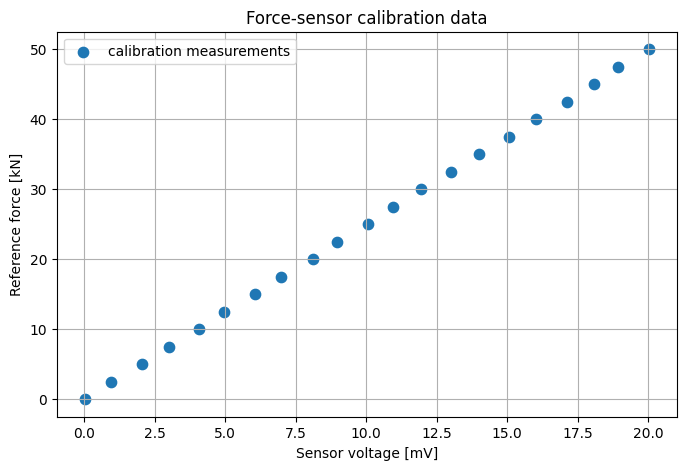

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(
    calibration_data["voltage_mV"],
    calibration_data["reference_force_kN"],
    s=55,
    label="calibration measurements",
)

ax.set_xlabel("Sensor voltage [mV]")
ax.set_ylabel("Reference force [kN]")
ax.set_title("Force-sensor calibration data")
ax.grid(True)
ax.legend()

plt.show()


### 🧠 What should you notice?

The relationship is close to linear, but the points do not lie exactly on one line.
That scatter represents measurement variation.

Regression is appropriate here because we want a trend that represents the
calibration relationship. Exact interpolation would force the model through every
noisy measurement.


## 📂 5.1.3 Features, targets and array shape

scikit-learn expects the feature matrix `X` to have shape
`(n_samples, n_features)`. Even a model with one feature therefore uses a two-
dimensional table.

The target `y` usually has shape `(n_samples,)` for a single regression output.
Keeping meaningful column names makes the model inputs easier to audit.


In [ ]:
X = calibration_data[["voltage_mV"]]
y = calibration_data["reference_force_kN"]

shape_table = pd.DataFrame({
    "object": ["X", "y"],
    "shape": [str(X.shape), str(y.shape)],
    "meaning": [
        "21 samples and 1 feature",
        "21 target values",
    ],
})

shape_table


,object,shape,meaning
0,X,"(21, 1)",21 samples and 1 feature
1,y,"(21,)",21 target values


## 📂 5.1.4 Training and validation data

If we evaluate a model only on the data used to fit it, the result can be too
optimistic. We therefore withhold part of the dataset.

`random_state` makes the split reproducible. This matters when students, tutors and
reviewers need to obtain the same results.

Week 5.6 will examine cases where a random split is inappropriate, including grouped,
time-ordered and distribution-shifted data.


In [ ]:
X_train, X_validation, y_train, y_validation = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
)

split_summary = pd.DataFrame({
    "subset": ["training", "validation"],
    "samples": [len(X_train), len(X_validation)],
    "minimum_voltage_mV": [
        X_train["voltage_mV"].min(),
        X_validation["voltage_mV"].min(),
    ],
    "maximum_voltage_mV": [
        X_train["voltage_mV"].max(),
        X_validation["voltage_mV"].max(),
    ],
})

split_summary


,subset,samples,minimum_voltage_mV,maximum_voltage_mV
0,training,15,2.0569,20.0143
1,validation,6,0.0300,17.1017


### ⚠️ Engineering warning

A random split checks whether the model predicts similar unseen samples from the same
dataset. It does not prove the model will work for:

* a different sensor;
* a different temperature range;
* forces outside the calibration range;
* a changed data-acquisition system; or
* future data after the sensor has drifted.


## 📂 5.1.5 Fitting a linear regression model

The scikit-learn workflow is consistent across many machine-learning methods:

1. create an estimator;
2. call `fit(X_train, y_train)`;
3. call `predict(X_new)`; and
4. evaluate predictions using withheld data and engineering checks.


In [ ]:
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

coefficient_table = pd.DataFrame({
    "parameter": ["intercept", "voltage coefficient"],
    "value": [linear_model.intercept_, linear_model.coef_[0]],
    "units": ["kN", "kN per mV"],
})

coefficient_table


,parameter,value,units
0,intercept,-0.0902,kN
1,voltage coefficient,2.5062,kN per mV


### 🧩 Interpreting the fitted parameters

The fitted equation is

$$
\widehat{F} = \hat{\beta}_0 + \hat{\beta}_1 V,
$$

where $V$ is voltage in millivolts and $\widehat{F}$ is predicted force in
kilonewtons.

* The coefficient has units of **kN per mV**.
* The intercept is the predicted force at zero measured voltage.

An intercept can be mathematically necessary without having a useful physical
interpretation. We should not interpret it outside the observed data range without
understanding the sensor and acquisition system.


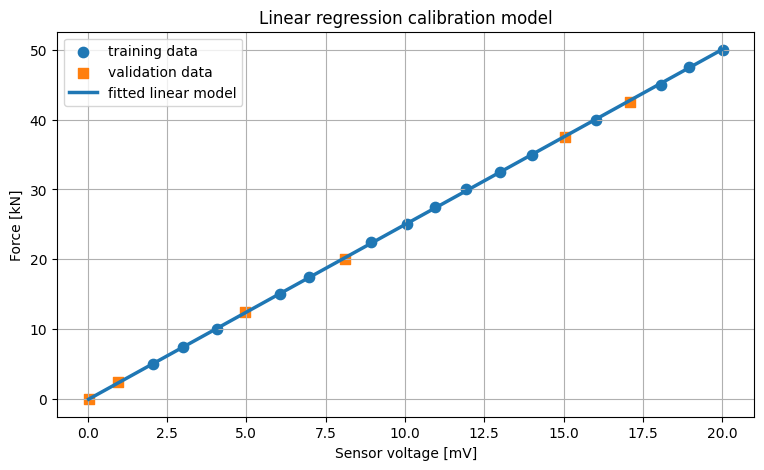

In [ ]:
voltage_grid = pd.DataFrame({
    "voltage_mV": np.linspace(
        calibration_data["voltage_mV"].min(),
        calibration_data["voltage_mV"].max(),
        250,
    )
})

force_grid_prediction = linear_model.predict(voltage_grid)

fig, ax = plt.subplots(figsize=(9, 5))

ax.scatter(
    X_train["voltage_mV"],
    y_train,
    s=55,
    label="training data",
)
ax.scatter(
    X_validation["voltage_mV"],
    y_validation,
    marker="s",
    s=60,
    label="validation data",
)
ax.plot(
    voltage_grid["voltage_mV"],
    force_grid_prediction,
    linewidth=2.5,
    label="fitted linear model",
)

ax.set_xlabel("Sensor voltage [mV]")
ax.set_ylabel("Force [kN]")
ax.set_title("Linear regression calibration model")
ax.grid(True)
ax.legend()

plt.show()


## 📂 5.1.6 Predictions and residuals

A prediction is useful only when we understand its error. For every validation
sample, we can compare the measured target with the model prediction.

Positive residuals mean the observed force is larger than predicted. Negative
residuals mean the observed force is smaller than predicted.


In [ ]:
validation_prediction = linear_model.predict(X_validation)

validation_results = X_validation.copy()
validation_results["observed_force_kN"] = y_validation
validation_results["predicted_force_kN"] = validation_prediction
validation_results["residual_kN"] = (
    validation_results["observed_force_kN"]
    - validation_results["predicted_force_kN"]
)

validation_results.sort_values("voltage_mV")


,voltage_mV,observed_force_kN,predicted_force_kN,residual_kN
0,0.0300,0.0,-0.0149,0.0149
1,0.9616,2.5,2.3196,0.1804
5,4.9501,12.5,12.3154,0.1846
8,8.1159,20.0,20.2494,-0.2494
15,15.0599,37.5,37.6523,-0.1523
17,17.1017,42.5,42.7694,-0.2694


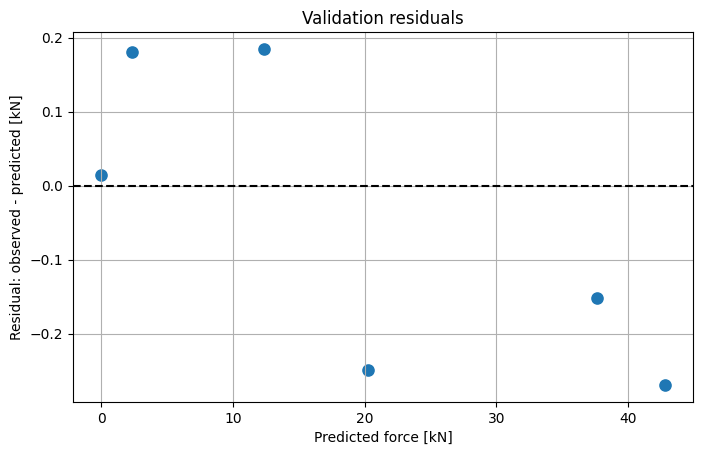

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4.8))

ax.scatter(validation_prediction, validation_results["residual_kN"], s=65)
ax.axhline(0.0, color="black", linestyle="--")

ax.set_xlabel("Predicted force [kN]")
ax.set_ylabel("Residual: observed - predicted [kN]")
ax.set_title("Validation residuals")
ax.grid(True)

plt.show()


### 🧠 What should you notice?

A useful residual plot should not show a strong curve, drift or funnel shape.

With only a few validation points we should be cautious: an apparently random pattern
is not proof that every model assumption is satisfied. It is one piece of evidence.


## 📂 5.1.7 Validation metrics and a baseline

We will calculate three familiar regression metrics:

* **MAE:** mean absolute error, in the target units;
* **RMSE:** root mean squared error, also in the target units and more sensitive to
  large residuals; and
* **R²:** the fraction of target variation explained relative to a mean-prediction
  reference.

Week 5.5 will examine these metrics in detail. Here they provide an initial check.

We also compare the model with a baseline that predicts the training-set mean for
every validation sample.


In [ ]:
def regression_metrics(y_true, y_pred):
    # Return common regression metrics in a labelled dictionary.
    mse = mean_squared_error(y_true, y_pred)
    return {
        "MAE_kN": mean_absolute_error(y_true, y_pred),
        "RMSE_kN": np.sqrt(mse),
        "R2": r2_score(y_true, y_pred),
    }


baseline_prediction = np.full(
    shape=len(y_validation),
    fill_value=y_train.mean(),
)

metric_comparison = pd.DataFrame({
    "linear regression": regression_metrics(
        y_validation,
        validation_prediction,
    ),
    "mean baseline": regression_metrics(
        y_validation,
        baseline_prediction,
    ),
}).T

metric_comparison


,MAE_kN,RMSE_kN,R2
linear regression,0.1752,0.1936,0.9999
mean baseline,16.6111,18.1246,-0.2547


### ⚠️ Point of note

A high R² value does not guarantee that:

* the model is unbiased;
* the errors are acceptable for the engineering decision;
* the model will extrapolate safely;
* the relationship is causal; or
* the data represents future operating conditions.

Error must be judged using units, tolerances, consequences and the intended use.


## 📂 5.1.8 Checking the supported prediction range

`LinearRegression.predict` will return a value outside the training range. The method
does not automatically know whether that extrapolation is physically defensible.

A simple wrapper can report whether the requested voltage lies inside the calibration
support.


In [ ]:
def predict_force_with_warning(model, voltage_mV, training_voltage_mV):
    # Predict force and label interpolation-like support or extrapolation.
    voltage_values = np.atleast_1d(voltage_mV).astype(float)
    training_values = np.asarray(training_voltage_mV, dtype=float)

    inside_support = (
        (voltage_values >= training_values.min())
        & (voltage_values <= training_values.max())
    )

    query_table = pd.DataFrame({"voltage_mV": voltage_values})
    predicted_force = model.predict(query_table)

    return pd.DataFrame({
        "voltage_mV": voltage_values,
        "predicted_force_kN": predicted_force,
        "support": np.where(
            inside_support,
            "inside calibration range",
            "extrapolation",
        ),
    })


query_voltage_mV = [5.0, 12.5, 22.0]

predict_force_with_warning(
    linear_model,
    query_voltage_mV,
    X_train["voltage_mV"],
)


,voltage_mV,predicted_force_kN,support
0,5.0,12.4406,inside calibration range
1,12.5,31.2367,inside calibration range
2,22.0,55.0451,extrapolation


### ⚠️ Engineering warning

Being inside the minimum and maximum of one feature is only a basic support check.
For multiple features, the geometry of the training domain is more complicated.

Later in Week 5 we will examine model behaviour and training-data coverage in higher-
dimensional feature spaces.


## 📂 5.1.9 Sensitivity to an unusual observation

Least squares gives large residuals strong influence because residuals are squared.
We can demonstrate this by simulating one corrupted calibration record.

The original dataset is not being corrected or rejected. This is a controlled
sensitivity experiment.


In [ ]:
calibration_with_outlier = calibration_data.copy()

# Controlled demonstration: corrupt one recorded voltage by +3 mV.
outlier_row = len(calibration_with_outlier) - 2
calibration_with_outlier.loc[outlier_row, "voltage_mV"] += 3.0

outlier_model = LinearRegression().fit(
    calibration_with_outlier[["voltage_mV"]],
    calibration_with_outlier["reference_force_kN"],
)

sensitivity_summary = pd.DataFrame({
    "model": ["original", "with one corrupted record"],
    "intercept_kN": [linear_model.intercept_, outlier_model.intercept_],
    "coefficient_kN_per_mV": [linear_model.coef_[0], outlier_model.coef_[0]],
    "predicted_force_at_15_mV_kN": [
        linear_model.predict(pd.DataFrame({"voltage_mV": [15.0]}))[0],
        outlier_model.predict(pd.DataFrame({"voltage_mV": [15.0]}))[0],
    ],
})

sensitivity_summary


,model,intercept_kN,coefficient_kN_per_mV,predicted_force_at_15_mV_kN
0,original,-0.0902,2.5062,37.5021
1,with one corrupted record,0.6741,2.3943,36.5889


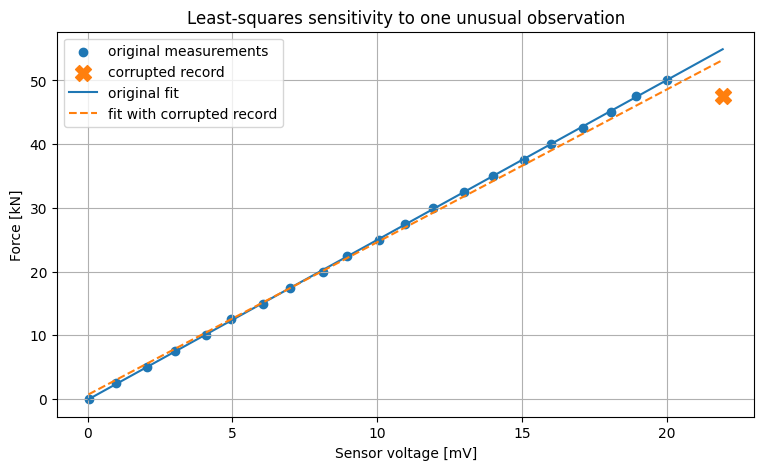

In [ ]:
comparison_grid = pd.DataFrame({
    "voltage_mV": np.linspace(
        calibration_with_outlier["voltage_mV"].min(),
        calibration_with_outlier["voltage_mV"].max(),
        250,
    )
})

fig, ax = plt.subplots(figsize=(9, 5))

ax.scatter(
    calibration_data["voltage_mV"],
    calibration_data["reference_force_kN"],
    label="original measurements",
)
ax.scatter(
    calibration_with_outlier.loc[outlier_row, "voltage_mV"],
    calibration_with_outlier.loc[outlier_row, "reference_force_kN"],
    marker="X",
    s=130,
    label="corrupted record",
)
ax.plot(
    comparison_grid["voltage_mV"],
    linear_model.predict(comparison_grid),
    label="original fit",
)
ax.plot(
    comparison_grid["voltage_mV"],
    outlier_model.predict(comparison_grid),
    "--",
    label="fit with corrupted record",
)

ax.set_xlabel("Sensor voltage [mV]")
ax.set_ylabel("Force [kN]")
ax.set_title("Least-squares sensitivity to one unusual observation")
ax.grid(True)
ax.legend()

plt.show()


### 🧠 What should you notice?

One unusual point changes the fitted slope, intercept and predictions across the
domain. The point may represent:

* a data-entry error;
* sensor saturation;
* a changed test condition;
* a real but rare operating mode; or
* an incorrectly matched feature and target.

We should investigate its cause rather than automatically deleting it.


## 📂 5.1.10 Multiple linear regression and temperature compensation

Real sensors may drift with temperature. Multiple linear regression extends the model
to several features:

$$
\hat{y} = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \cdots + \beta_p x_p.
$$

The demonstration below learns from voltage and temperature. All code is complete and
runs without editing.


In [ ]:
rng = np.random.default_rng(5102)
n_samples = 90

force_kN = rng.uniform(0.0, 50.0, n_samples)
temperature_C = rng.uniform(5.0, 45.0, n_samples)

voltage_mV = (
    0.020
    + 0.400 * force_kN
    + 0.012 * (temperature_C - 20.0)
    + rng.normal(0.0, 0.060, n_samples)
)

compensated_data = pd.DataFrame({
    "voltage_mV": voltage_mV,
    "temperature_C": temperature_C,
    "force_kN": force_kN,
})

compensated_data.head()


,voltage_mV,temperature_C,force_kN
0,19.7203,5.4306,49.7505
1,1.8033,10.1643,4.6732
2,19.1427,25.5583,47.3666
3,2.1654,41.8680,4.9734
4,5.2380,18.9507,13.1535


In [ ]:
X_compensated = compensated_data[["voltage_mV", "temperature_C"]]
y_compensated = compensated_data["force_kN"]

Xc_train, Xc_validation, yc_train, yc_validation = train_test_split(
    X_compensated,
    y_compensated,
    test_size=0.25,
    random_state=42,
)

voltage_only_model = LinearRegression().fit(
    Xc_train[["voltage_mV"]],
    yc_train,
)
temperature_compensated_model = LinearRegression().fit(
    Xc_train,
    yc_train,
)

voltage_only_prediction = voltage_only_model.predict(
    Xc_validation[["voltage_mV"]]
)
compensated_prediction = temperature_compensated_model.predict(Xc_validation)

compensation_comparison = pd.DataFrame({
    "voltage only": regression_metrics(
        yc_validation,
        voltage_only_prediction,
    ),
    "voltage and temperature": regression_metrics(
        yc_validation,
        compensated_prediction,
    ),
}).T

compensation_comparison


,MAE_kN,RMSE_kN,R2
voltage only,0.3624,0.4379,0.9990
voltage and temperature,0.1267,0.1556,0.9999


In [ ]:
multiple_coefficient_table = pd.DataFrame({
    "parameter": ["intercept", *temperature_compensated_model.feature_names_in_],
    "value": [
        temperature_compensated_model.intercept_,
        *temperature_compensated_model.coef_,
    ],
    "units": ["kN", "kN per mV", "kN per degree C"],
})

multiple_coefficient_table


,parameter,value,units
0,intercept,0.5173,kN
1,voltage_mV,2.5017,kN per mV
2,temperature_C,-0.0292,kN per degree C


### Visualising a regression model with two features

A model with two features can be visualised as a surface. The horizontal axes show
voltage and temperature, while the vertical axis shows predicted force.

Because this is a linear regression model, the fitted surface is a plane. Its tilt in
the temperature direction represents the temperature-compensation coefficient.


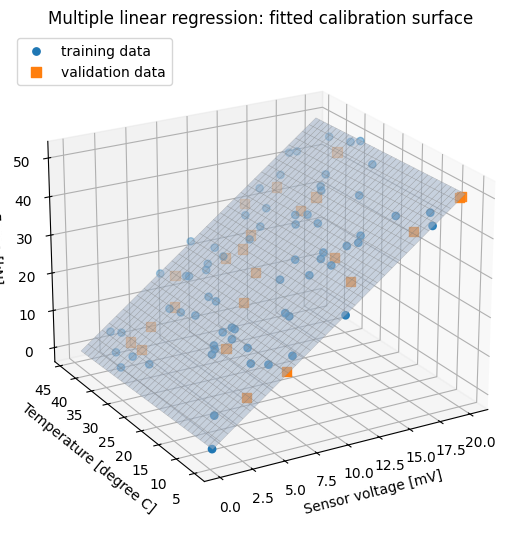

In [ ]:
voltage_axis = np.linspace(
    X_compensated["voltage_mV"].min(),
    X_compensated["voltage_mV"].max(),
    35,
)
temperature_axis = np.linspace(
    X_compensated["temperature_C"].min(),
    X_compensated["temperature_C"].max(),
    35,
)

voltage_surface, temperature_surface = np.meshgrid(
    voltage_axis,
    temperature_axis,
)

surface_features = pd.DataFrame({
    "voltage_mV": voltage_surface.ravel(),
    "temperature_C": temperature_surface.ravel(),
})
force_surface = temperature_compensated_model.predict(
    surface_features
).reshape(voltage_surface.shape)

fig = plt.figure(figsize=(9, 6.5))
ax = fig.add_subplot(111, projection="3d")

fitted_surface = ax.plot_surface(
    voltage_surface,
    temperature_surface,
    force_surface,
    color="lightsteelblue",
    alpha=0.55,
    edgecolor="grey",
    linewidth=0.25,
)
ax.scatter(
    Xc_train["voltage_mV"],
    Xc_train["temperature_C"],
    yc_train,
    s=28,
    label="training data",
)
ax.scatter(
    Xc_validation["voltage_mV"],
    Xc_validation["temperature_C"],
    yc_validation,
    marker="s",
    s=45,
    label="validation data",
)

ax.set_xlabel("Sensor voltage [mV]")
ax.set_ylabel("Temperature [degree C]")
ax.set_zlabel("Force [kN]")
ax.set_title("Multiple linear regression: fitted calibration surface")
ax.view_init(elev=22, azim=-120)
ax.legend(loc="upper left")

plt.show()


### Does temperature compensation remove systematic error?

A useful comparison is to plot residuals against the feature that was omitted from the
simpler model. If temperature matters, the voltage-only residuals should change with
temperature. Adding temperature should reduce that structure.


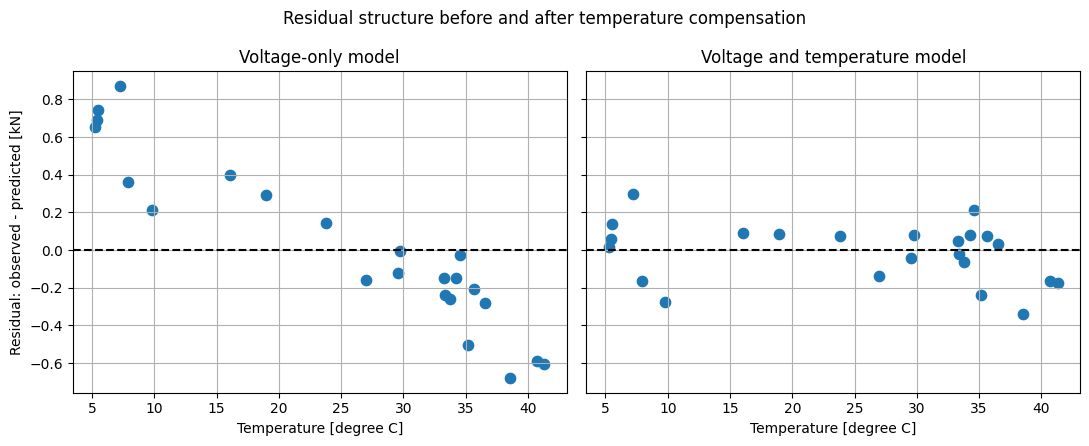

In [ ]:
voltage_only_residual = yc_validation.to_numpy() - voltage_only_prediction
compensated_residual = yc_validation.to_numpy() - compensated_prediction

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharex=True, sharey=True)

axes[0].scatter(
    Xc_validation["temperature_C"],
    voltage_only_residual,
    s=55,
)
axes[0].axhline(0.0, color="black", linestyle="--")
axes[0].set_title("Voltage-only model")

axes[1].scatter(
    Xc_validation["temperature_C"],
    compensated_residual,
    s=55,
)
axes[1].axhline(0.0, color="black", linestyle="--")
axes[1].set_title("Voltage and temperature model")

for ax in axes:
    ax.set_xlabel("Temperature [degree C]")
    ax.grid(True)

axes[0].set_ylabel("Residual: observed - predicted [kN]")
fig.suptitle("Residual structure before and after temperature compensation")
fig.tight_layout()

plt.show()


### 🧠 Interpretation

Adding temperature should reduce validation error because the synthetic sensor signal
contains temperature drift.

The temperature coefficient represents the change in predicted force associated with
a one-degree temperature increase **while voltage is held constant**. This conditional
interpretation matters whenever a model has multiple features.

In the 3D figure, this effect appears as the tilt of the fitted plane in the
temperature direction. In the residual comparison, the compensated model should show
less temperature-related structure and smaller errors.

A coefficient is not automatically a causal effect. It describes the fitted
relationship in the available data.


## 📂 5.1.11 Optional interactive sensitivity demonstration

Run the cell below. If `ipywidgets` is available, move the slider to see how one
corrupted voltage measurement changes the fitted calibration line. No code editing is
required. A static demonstration is shown if widgets are unavailable.


In [ ]:
def plot_outlier_sensitivity(voltage_shift_mV=0.0):
    demo_data = calibration_data.copy()
    demo_data.loc[outlier_row, "voltage_mV"] += voltage_shift_mV

    demo_model = LinearRegression().fit(
        demo_data[["voltage_mV"]],
        demo_data["reference_force_kN"],
    )

    x_demo = pd.DataFrame({
        "voltage_mV": np.linspace(
            demo_data["voltage_mV"].min(),
            demo_data["voltage_mV"].max(),
            200,
        )
    })

    fig, ax = plt.subplots(figsize=(8, 4.8))
    ax.scatter(
        demo_data["voltage_mV"],
        demo_data["reference_force_kN"],
        label="calibration data",
    )
    ax.scatter(
        demo_data.loc[outlier_row, "voltage_mV"],
        demo_data.loc[outlier_row, "reference_force_kN"],
        marker="X",
        s=130,
        label="shifted record",
    )
    ax.plot(
        x_demo["voltage_mV"],
        demo_model.predict(x_demo),
        label="refitted model",
    )
    ax.set_xlabel("Sensor voltage [mV]")
    ax.set_ylabel("Force [kN]")
    ax.set_title(
        f"Voltage shift = {voltage_shift_mV:.1f} mV; "
        f"slope = {demo_model.coef_[0]:.3f} kN/mV"
    )
    ax.grid(True)
    ax.legend()
    plt.show()


try:
    from ipywidgets import FloatSlider, interact

    interact(
        plot_outlier_sensitivity,
        voltage_shift_mV=FloatSlider(
            value=0.0,
            min=-4.0,
            max=4.0,
            step=0.5,
            description="shift [mV]",
            continuous_update=False,
        ),
    )
except ImportError:
    print("ipywidgets is unavailable; showing the static +3 mV scenario.")
    plot_outlier_sensitivity(voltage_shift_mV=3.0)


interactive(children=(FloatSlider(value=0.0, continuous_update=False, description='shift [mV]', max=4.0, min=-…

## 📂 5.1.12 Method limitations and engineering checks

Before using a linear regression model, ask:

1. Is the target continuous and meaningful?
2. Is a linear relationship plausible over the intended domain?
3. Are feature and target units documented?
4. Is the training data representative of use conditions?
5. Was validation data kept separate from fitting?
6. Do residuals reveal curvature, drift or changing variance?
7. Are unusual observations understood?
8. Are predictions inside the supported feature domain?
9. Does the model outperform an appropriate baseline?
10. Is the error acceptable for the engineering consequence?

Linear regression is often a strong baseline even when a more flexible model is later
selected.


## 📂 5.1.13 Useful packages and functions

| Package | Function or attribute | Purpose | Important output or caution |
|---|---|---|---|
| `pandas` | `DataFrame` | Store labelled feature and target data | Preserve meaningful names and units |
| `sklearn.model_selection` | `train_test_split` | Create reproducible holdout data | Random splitting is not valid for every dataset |
| `sklearn.linear_model` | `LinearRegression` | Fit ordinary least squares | Sensitive to unusual observations |
| fitted estimator | `coef_`, `intercept_` | Inspect learned parameters | Interpret with units and conditional meaning |
| fitted estimator | `predict` | Predict targets for new features | Does not automatically warn about extrapolation |
| `sklearn.metrics` | `mean_absolute_error` | Typical absolute error in target units | Treats errors linearly |
| `sklearn.metrics` | `mean_squared_error` | Mean squared error | Square root gives RMSE in target units |
| `sklearn.metrics` | `r2_score` | Compare against a mean-prediction reference | High R² alone does not prove model adequacy |


## 📂 5.1.14 Engineering workflow and summary

A defensible first regression workflow is:

1. define the prediction task and units;
2. inspect and visualise the data;
3. separate features, target, training data and validation data;
4. fit a baseline and a linear regression model;
5. interpret the learned parameters;
6. evaluate validation errors and residuals;
7. check feature-domain support and sensitivity to unusual data; and
8. communicate assumptions, limitations and intended use.

Linear regression is valuable because it makes this workflow visible. Later Week 5
methods will be more flexible, but they still require the same discipline.


## 📚 References

* scikit-learn developers, *LinearRegression*, stable documentation.
* scikit-learn developers, *Model evaluation: quantifying the quality of predictions*,
  stable documentation.
* scikit-learn developers, *Common pitfalls and recommended practices*, stable
  documentation.
* NIST/SEMATECH, *e-Handbook of Statistical Methods: Linear Least Squares
  Regression*.
* NIST/SEMATECH, *e-Handbook of Statistical Methods: Linearity of the Gauge*.

## 🤖 AI Acknowledgment

Generative AI was used to help structure explanations, develop teaching examples and
review code. The teaching team remains responsible for the mathematical content,
engineering interpretation, source selection and final notebook.
